In [27]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path
from PIL import Image

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


In [28]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [29]:
splits=[]
types=[]
print("Dataset path:", path)
print("\nDataset structure:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print(f"Folder:  {item}/")
    else:
        print(f"File {item}")

# print(os.listdir(path))
for ele in os.listdir(path + "/chest_xray"):
  if ele =="chest_xray" or ele =="__MACOSX":
    continue
  splits.append(ele)

for split in splits:
  t=os.listdir(path + "/chest_xray/" + split)
  for ele in t:
    if ele in types:
      continue
    types.append(ele)
print(splits)
print(types)


Dataset path: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2

Dataset structure:
Folder:  chest_xray/
['test', 'train', 'val']
['NORMAL', 'PNEUMONIA']


In [30]:
from pathlib import Path
from PIL import Image

root = Path(path)
IMG_SIZE = (180, 180)

for split in splits:
    split_path = root / "chest_xray" / split

    if split_path.exists():
        print(f"\n{split}")

        for class_name in types:
            class_path = split_path / class_name

            if class_path.exists():

                images = []

                for f in class_path.iterdir():
                    if f.is_file():
                        images.append(f)

                print(f"{class_name}: {len(images)} images")

                processed_images = []

                for image_path in images:
                    try:
                        with Image.open(image_path) as image:
                            image = image.convert("RGB")
                            image = image.resize(IMG_SIZE)

                            processed_images.append(image.copy())

                    except Exception as e:
                        print(f"Erreur avec {image_path}: {e}")

                print(
                    f"Images traitées: {len(processed_images)}"
                )


test
NORMAL: 234 images
Images traitées: 234
PNEUMONIA: 390 images
Images traitées: 390

train
NORMAL: 1341 images
Images traitées: 1341
PNEUMONIA: 3875 images
Images traitées: 3875

val
NORMAL: 8 images
Images traitées: 8
PNEUMONIA: 8 images
Images traitées: 8



NORMAL: 4 images

PNEUMONIA: 4 images


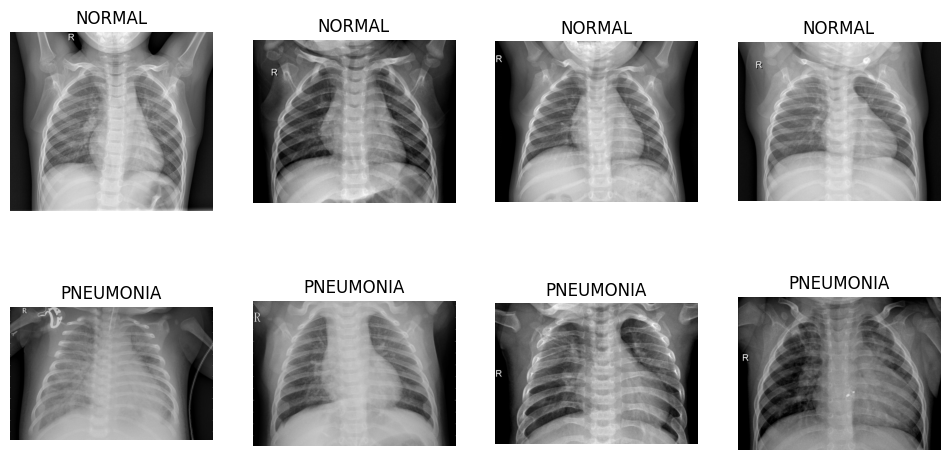

In [31]:
train_dir = Path(path) / "chest_xray" / "train"

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, class_name in enumerate(types):
    images = list((train_dir / class_name).glob("*.jpeg"))[:4]
    print(f"\n{class_name}: {len(images)} images")
    for col, img_path in enumerate(images):
        axes[row, col].imshow(Image.open(img_path), cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.show()

NORMAL: 1341 images (25.7%)
PNEUMONIA: 3875 images (74.3%)


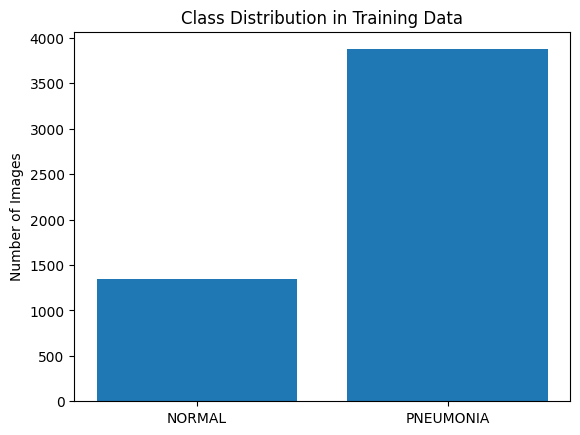

In [32]:
train_dir = Path(path) / "chest_xray" / "train"

counts = {
    name: len(list((train_dir / name).glob("*.jpeg")))
    for name in types
}
total = sum(counts.values())

for name, n in counts.items():
    print(f"{name}: {n} images ({n / total * 100:.1f}%)")

plt.bar(counts.keys(), counts.values())
plt.title("Class Distribution in Training Data")
plt.ylabel("Number of Images")
plt.show()

In [33]:
classes = np.array([0, 1])   # 0 = NORMAL, 1 = PNEUMONIA
y_train = np.array([0] * counts["NORMAL"] + [1] * counts["PNEUMONIA"])

weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}

print("Class weights:", class_weight_dict)
print("Class weights:", class_weight_dict)

Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}
Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [34]:
from pathlib import Path
from PIL import Image

valid_images = []
corrupted_images = []

for split in splits:
    for class_name in types:
        class_path = root / split / class_name

        if not class_path.exists():
            print(f"Dossier introuvable : {class_path}")
            continue

        for img_path in class_path.iterdir():
            if not img_path.is_file():
                continue

            try:
                with Image.open(img_path) as img:
                    img.verify()

                valid_images.append(img_path)

            except Exception as e:
                corrupted_images.append(img_path)
                print(f"Image invalide : {img_path} | Erreur : {e}")

print("Images valides :", len(valid_images))
print("Images corrompues :", len(corrupted_images))

Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/test/NORMAL
Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/test/PNEUMONIA
Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/train/NORMAL
Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/train/PNEUMONIA
Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/val/NORMAL
Dossier introuvable : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/val/PNEUMONIA
Images valides : 0
Images corrompues : 0


In [35]:
train_dir = Path(path) / "chest_xray" / "train"
test_dir = Path(path) / "chest_xray" / "test"

CLASS_NAMES=["NORMAL", "PNEUMONIA"]
SEED=42

common = dict(
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=32,
)

train_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2,
    subset="training",
    seed=SEED,
    **common)

val_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    **common)

test_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    **common)

print("Classes:", train_ds_cnn.class_names)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [36]:
# Normalisation des pixels entre 0 et 1
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [37]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [38]:
# Evaluation helper: used for the CNN, transfer learning and fine-tuning
results = {}


def evaluate_classifier(name, model, dataset, threshold=0.5):
    y_true = []
    y_prob = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        y_prob.extend(probabilities.ravel())
        y_true.extend(labels.numpy().ravel())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }

    results[name] = {
        "metrics": metrics,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
    }

    print(f"\n{name}")
    for metric_name, value in metrics.items():
        print(f"{metric_name.replace('_', '-').title()}: {value:.4f}")

    return results[name]


In [39]:

# 13. Construire le modèle CNN
model_cnn = models.Sequential([
    # Input
    layers.Input(shape=(180, 180, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output
    layers.Dense(1, activation="sigmoid")
])

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
import tensorflow as tf
# 14. Compiler et entraîner le modèle
# Compile the model
model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)



In [41]:
# Train the model
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_chestscan_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.3821 - loss: 0.6933 - precision: 0.8170 - recall: 0.1937 - val_accuracy: 0.6309 - val_loss: 0.6670 - val_precision: 0.8822 - val_recall: 0.5945
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.6792 - loss: 0.5770 - precision: 0.9097 - recall: 0.6242 - val_accuracy: 0.6932 - val_loss: 0.5163 - val_precision: 0.9438 - val_recall: 0.6348
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.7802 - loss: 0.4251 - precision: 0.9482 - recall: 0.7400 - val_accuracy: 0.8035 - val_loss: 0.4244 - val_precision: 0.9884 - val_recall: 0.7506
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8301 - loss: 0.3504 - precision: 0.9603 - recall: 0.7990 - val_accuracy: 0.8485 - val_loss: 0.3296 - val_precision: 0.9818 - val_recall: 0.8161
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8565 - loss: 0.3093 - precision: 0.9672 - recall: 0.8316 - val_accuracy: 0.8917 - val_los

In [42]:
# Normal CNN evaluation
evaluate_classifier("Normal CNN", model_cnn, test_ds_cnn)



Normal CNN
Accuracy: 0.5689
Precision: 0.8854
Recall: 0.3564
F1: 0.5082
Roc-Auc: 0.6831


{'metrics': {'accuracy': 0.5689102564102564,
  'precision': 0.8853503184713376,
  'recall': 0.3564102564102564,
  'f1': 0.5082266910420475,
  'roc_auc': 0.6831032215647601},
 'y_true': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

Transfer Learming Steps

In [43]:
# Step 1 — Prepare the dataset
AUTOTUNE = tf.data.AUTOTUNE

common_mn = dict(
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=(224, 224),
    batch_size=32,
)

train_ds_mn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    **common_mn)

val_ds_mn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    **common_mn
    )
test_ds_mn = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    **common_mn)

train_ds_mn = train_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)
val_ds_mn   = val_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)
test_ds_mn  = test_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


In [44]:
# Step 2 — Load the pretrained model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Step 3 — Freeze the pretrained layers
base_model.trainable = False

# Step 4 — Add a new classifier
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model_mn = models.Model(inputs, outputs)



In [45]:
# Step 5 - Compile and train the classifier head (base frozen)
base_model.trainable = False

model_mn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_mn = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss",
                                      patience=3,
                                      restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_mobilenetv2_tl.keras",
                                        monitor="val_loss",
                                        save_best_only=True)
]

history_mn = model_mn.fit(
    train_ds_mn,
    validation_data=val_ds_mn,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks_mn
)

# Step 6 - Evaluate transfer learning alone (base frozen)
# This happens BEFORE unfreezing, so the metrics belong to the frozen model.
evaluate_classifier("Transfer Learning (frozen)", model_mn, test_ds_mn)
model_mn.save("best_mobilenetv2_tl.keras")

# Step 7 - Unfreeze the last 20 layers of MobileNetV2 (fine-tuning)
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Step 8 - Recompile model_mn with a very low learning rate, then fine-tune
model_mn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_mobilenetv2_ft.keras", monitor="val_loss", save_best_only=True)
]

history_ft = model_mn.fit(
    train_ds_mn,
    validation_data=val_ds_mn,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=callbacks_ft
)

# Step 9 - Evaluate fine-tuning alone
evaluate_classifier("Fine-Tuning", model_mn, test_ds_mn)


Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 16s 69ms/step - accuracy: 0.8314 - loss: 0.3772 - precision: 0.9256 - recall: 0.8311 - val_accuracy: 0.9521 - val_loss: 0.1216 - val_precision: 0.9856 - val_recall: 0.9509
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.9548 - loss: 0.1257 - precision: 0.9884 - recall: 0.9494 - val_accuracy: 0.9540 - val_loss: 0.1203 - val_precision: 0.9947 - val_recall: 0.9446
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.9526 - loss: 0.1201 - precision: 0.9925 - recall: 0.9422 - val_accuracy: 0.9329 - val_loss: 0.1561 - val_precision: 0.9945 - val_recall: 0.9169
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9616 - loss: 0.0983 - precision: 0.9939 - recall: 0.9529 - val_accuracy: 0.9463 - val_loss: 0.1289 - val_precision: 0.9946 - val_recall: 0.9345
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.9615 - loss: 0.0962 - precision: 0.9923 - recall: 0.9547 - val_accuracy: 0.9569 - val_lo

2026-10-22 17:18:59.322423: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence



Transfer Learning (frozen)
Accuracy: 0.8333
Precision: 0.7907
Recall: 0.9974
F1: 0.8821
Roc-Auc: 0.9652
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step - accuracy: 0.8812 - loss: 1.0358 - precision: 0.8776 - recall: 0.9787 - val_accuracy: 0.9741 - val_loss: 0.0867 - val_precision: 0.9740 - val_recall: 0.9924
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9517 - loss: 0.1588 - precision: 0.9802 - recall: 0.9534 - val_accuracy: 0.9741 - val_loss: 0.0810 - val_precision: 0.9800 - val_recall: 0.9861
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.9572 - loss: 0.1220 - precision: 0.9847 - recall: 0.9567 - val_accuracy: 0.9722 - val_loss: 0.0803 - val_precision: 0.9811 - val_recall: 0.9824
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - accuracy: 0.9556 - loss: 0.1263 - precision: 0.9831 - recall: 0.9555 - val_accuracy: 0.9732 - val_loss: 0.0795 - val_precision: 0.9848 - val_recall: 0.9798
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/st

{'metrics': {'accuracy': 0.8349358974358975,
  'precision': 0.7958762886597938,
  'recall': 0.9897435897435898,
  'f1': 0.8822857142857143,
  'roc_auc': 0.9619055445978523},
 'y_true': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

                            Accuracy  Precision  Recall  F1-score  ROC-AUC
Normal CNN                    0.5689     0.8854  0.3564    0.5082   0.6831
Transfer Learning (frozen)    0.8333     0.7907  0.9974    0.8821   0.9652
Fine-Tuning                   0.8349     0.7959  0.9897    0.8823   0.9619


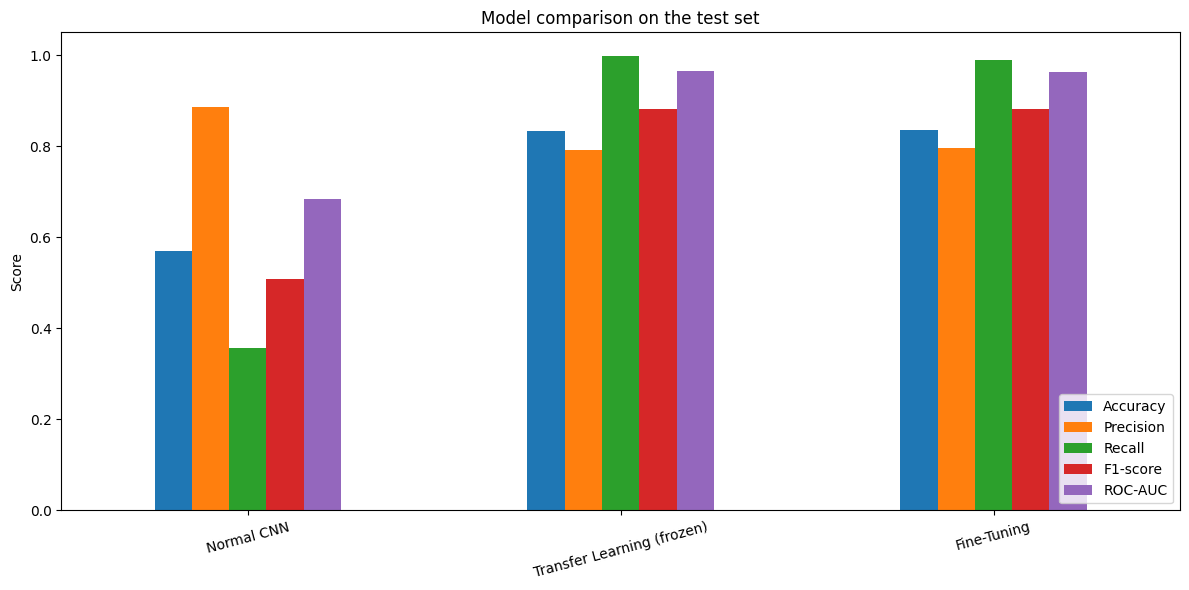

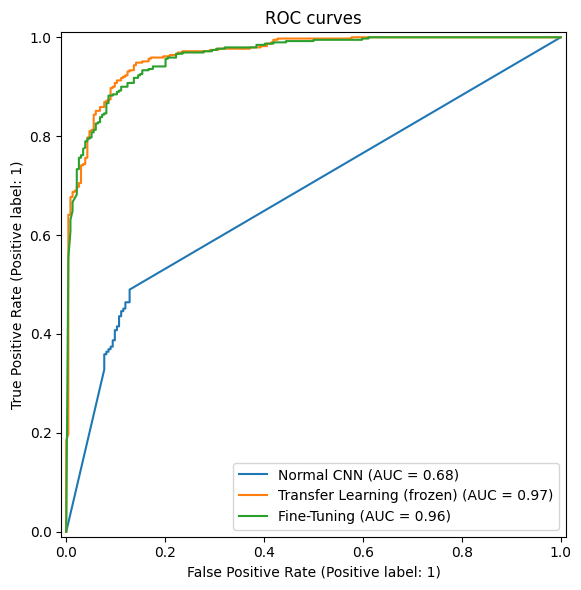

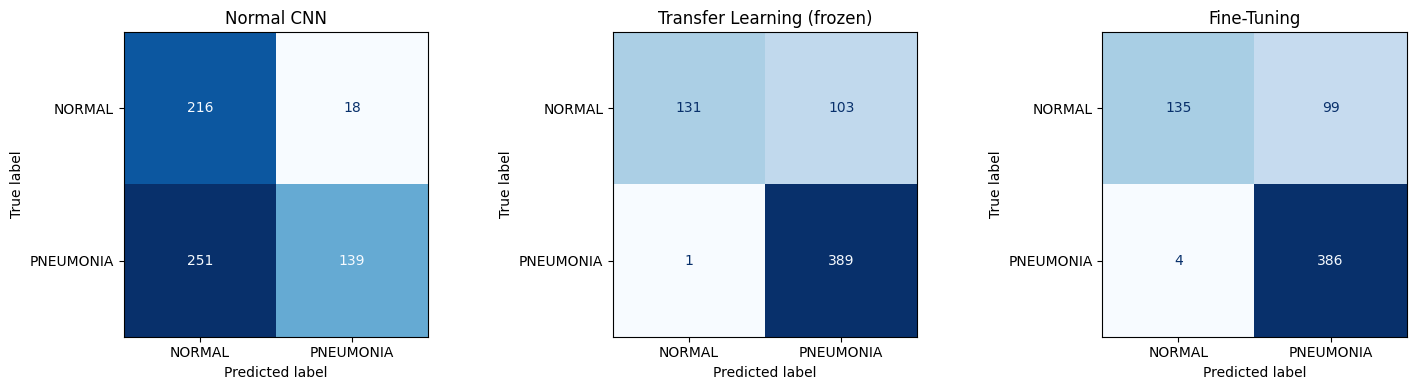

In [46]:
# Comparison of all models on the test set
comparison = pd.DataFrame(
    {name: res["metrics"] for name, res in results.items()}
).T

comparison = comparison[["accuracy", "precision", "recall", "f1", "roc_auc"]]
comparison.columns = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

print(comparison.round(4))

# Grouped bar chart
ax = comparison.plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))
ax.set_title("Model comparison on the test set")
ax.set_ylabel("Score")
ax.set_xticklabels(comparison.index, rotation=15)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, res in results.items():
    RocCurveDisplay.from_predictions(
        res["y_true"], res["y_prob"], name=name, ax=ax
    )
ax.set_title("ROC curves")
plt.tight_layout()
plt.show()

# Confusion matrices
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 4))
if len(results) == 1:
    axes = [axes]

for ax, (name, res) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        res["y_true"],
        res["y_pred"],
        display_labels=CLASS_NAMES,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()


In [47]:
model_cnn.save("chestscan_cnn.keras")
model_mn.save("chestscan_mobilenetv2.keras")

In [48]:
import json

metadata = {
    "image_size": [224, 224],
    "class_names": ["NORMAL", "PNEUMONIA"],
    "preprocessing": "mobilenet_v2_preprocess_input",
    "pixel_range_after_preprocessing": [-1, 1],
    "threshold": 0.5
}

with open("chestscan_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Modèles et métadonnées sauvegardés.")


with open("chestscan_metadata.json", "r") as file:
    metadata = json.load(file)

print(metadata)

Modèles et métadonnées sauvegardés.
{'image_size': [224, 224], 'class_names': ['NORMAL', 'PNEUMONIA'], 'preprocessing': 'mobilenet_v2_preprocess_input', 'pixel_range_after_preprocessing': [-1, 1], 'threshold': 0.5}
